<a href="https://colab.research.google.com/github/NandiniN2215/BIS_LAB/blob/main/Parallel_cellular_Smartenergy_Consumption_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


========== PCA OPTIMIZATION RESULTS ==========

Optimized Temperature Grid:
[[24.16 24.35 24.49 24.15]
 [24.63 24.75 24.35 24.5 ]
 [24.17 24.64 24.87 24.35]
 [24.49 24.17 24.64 24.77]]

Minimum Objective Value:
469.5791

Temperature for Each Room:
Room R1: 24.16 C
Room R2: 24.35 C
Room R3: 24.49 C
Room R4: 24.15 C
Room R5: 24.63 C
Room R6: 24.75 C
Room R7: 24.35 C
Room R8: 24.50 C
Room R9: 24.17 C
Room R10: 24.64 C
Room R11: 24.87 C
Room R12: 24.35 C
Room R13: 24.49 C
Room R14: 24.17 C
Room R15: 24.64 C
Room R16: 24.77 C

========== PERFORMANCE COMPARISON ==========
Initial Objective Value: 1013.8794
Optimized Objective Value: 469.5791
Improvement Percentage: 53.68 %


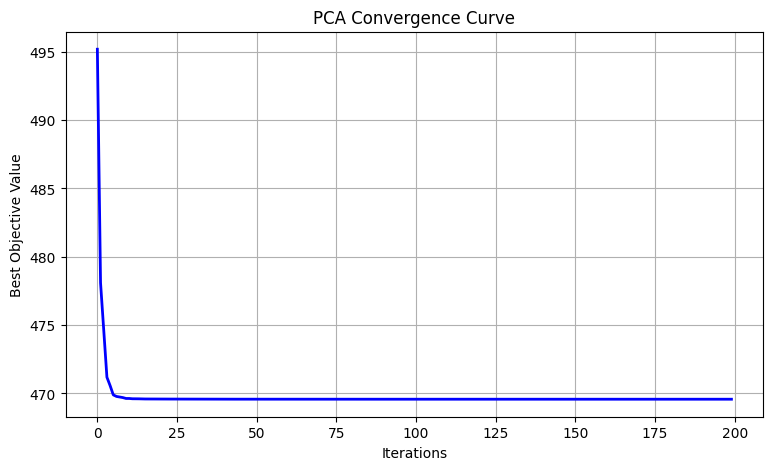

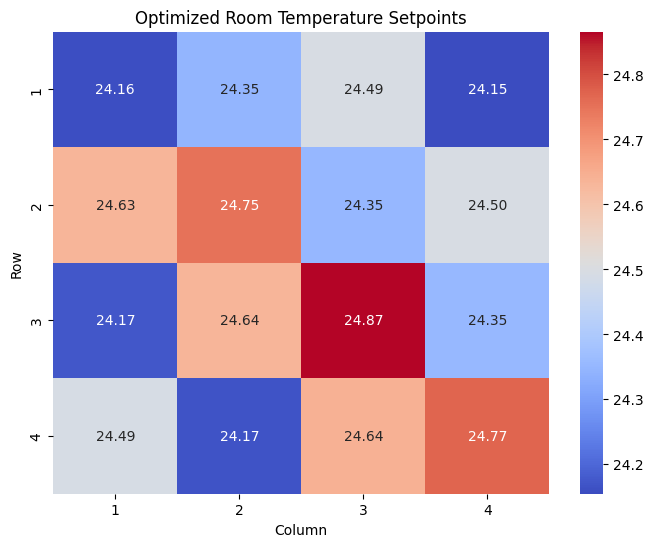

In [1]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. PROBLEM DEFINITION
# ==========================================

grid_size = 4
num_cells = 16

# Energy coefficients for 16 rooms
energy_coeff = np.array([
    2.0, 2.5, 3.0, 2.0,
    3.5, 4.0, 2.5, 3.0,
    2.0, 3.5, 4.5, 2.5,
    3.0, 2.0, 3.5, 4.0
]).reshape(grid_size, grid_size)

# Temperature constraints
min_temp = 20
max_temp = 26
preferred_temp = 23

# Objective function weights
comfort_weight = 5.0
coordination_weight = 0.1

# ==========================================
# 2. PCA PARAMETERS
# ==========================================

population = 5
max_iterations = 200

# Update parameters
own_weight = 0.5
neighbor_weight = 0.4
mutation_strength = 0.5

# ==========================================
# 3. NEIGHBORHOOD DEFINITION
# ==========================================

def get_neighbors(i, j):

    neighbors = []

    for di in [-1, 0, 1]:
        for dj in [-1, 0, 1]:

            if di == 0 and dj == 0:
                continue

            ni = i + di
            nj = j + dj

            if (0 <= ni < grid_size and
                0 <= nj < grid_size):

                neighbors.append((ni, nj))

    return neighbors


# ==========================================
# 4. LOCAL FITNESS FUNCTION
# ==========================================

def local_fitness(temp, i, j, neighbor_temps):

    a = energy_coeff[i, j]

    energy = a * (27 - temp)**2

    comfort = comfort_weight * (
        temp - preferred_temp
    )**2

    coordination = 0

    for neighbor_temp in neighbor_temps:

        coordination += coordination_weight * (
            temp - neighbor_temp
        )**2

    return energy + comfort + coordination


# ==========================================
# 5. GLOBAL FITNESS FUNCTION
# ==========================================

def global_fitness(temperature_grid):

    energy = np.sum(
        energy_coeff * (27 - temperature_grid)**2
    )

    comfort = comfort_weight * np.sum(
        (temperature_grid - preferred_temp)**2
    )

    coordination = 0

    # Count every adjacent pair once
    for i in range(grid_size):
        for j in range(grid_size):

            if i + 1 < grid_size:
                coordination += (
                    temperature_grid[i, j] -
                    temperature_grid[i + 1, j]
                )**2

            if j + 1 < grid_size:
                coordination += (
                    temperature_grid[i, j] -
                    temperature_grid[i, j + 1]
                )**2

    return (
        energy +
        comfort +
        coordination_weight * coordination
    )


# ==========================================
# 6. INITIALIZE CELL POPULATIONS
# ==========================================

cells = np.random.uniform(
    min_temp,
    max_temp,
    (grid_size, grid_size, population)
)

# Best solution found globally
global_best_fitness = float('inf')
global_best_grid = None

convergence = []


# ==========================================
# 7. PARALLEL CELLULAR ALGORITHM
# ==========================================

for iteration in range(max_iterations):

    # Store current cell populations
    old_cells = cells.copy()

    # Find best candidate in each cell using
    # neighboring best candidates from old state.

    cell_best = np.zeros((grid_size, grid_size))

    # First find provisional local bests
    for i in range(grid_size):
        for j in range(grid_size):

            best_temp = preferred_temp
            best_score = float('inf')

            for temp in old_cells[i, j]:

                score = local_fitness(
                    temp, i, j, []
                )

                if score < best_score:
                    best_score = score
                    best_temp = temp

            cell_best[i, j] = best_temp

    # Update every cell synchronously
    new_cells = np.zeros_like(old_cells)

    for i in range(grid_size):
        for j in range(grid_size):

            neighbors = get_neighbors(i, j)

            # Best temperatures of neighboring cells
            neighbor_temps = [
                cell_best[ni, nj]
                for ni, nj in neighbors
            ]

            # Find local best candidate
            scores = [
                local_fitness(
                    temp, i, j, neighbor_temps
                )
                for temp in old_cells[i, j]
            ]

            best_index = np.argmin(scores)
            own_best = old_cells[i, j, best_index]

            # Average neighboring best temperatures
            if len(neighbor_temps) > 0:
                neighbor_best = np.mean(neighbor_temps)
            else:
                neighbor_best = own_best

            # Preserve current best candidate (elitism)
            new_cells[i, j, 0] = own_best

            # Update remaining candidates
            for p in range(1, population):

                current = old_cells[i, j, p]

                r1 = np.random.rand()
                r2 = np.random.rand()

                updated = (
                    current
                    + own_weight * r1 * (own_best - current)
                    + neighbor_weight * r2 * (
                        neighbor_best - current
                    )
                    + np.random.normal(
                        0, mutation_strength
                    )
                )

                # Boundary handling
                updated = np.clip(
                    updated,
                    min_temp,
                    max_temp
                )

                new_cells[i, j, p] = updated

    # Replace all cell states together
    cells = new_cells

    # Construct current best temperature grid
    current_grid = np.zeros((grid_size, grid_size))

    for i in range(grid_size):
        for j in range(grid_size):

            neighbors = get_neighbors(i, j)

            neighbor_temps = [
                cell_best[ni, nj]
                for ni, nj in neighbors
            ]

            scores = [
                local_fitness(
                    temp, i, j, neighbor_temps
                )
                for temp in cells[i, j]
            ]

            current_grid[i, j] = cells[
                i, j, np.argmin(scores)
            ]

    # Evaluate complete grid
    current_fitness = global_fitness(current_grid)

    # Track global best solution
    if current_fitness < global_best_fitness:

        global_best_fitness = current_fitness
        global_best_grid = current_grid.copy()

    convergence.append(global_best_fitness)


# ==========================================
# 8. DISPLAY FINAL RESULTS
# ==========================================

print("\n========== PCA OPTIMIZATION RESULTS ==========")

print("\nOptimized Temperature Grid:")

print(np.round(global_best_grid, 2))

print("\nMinimum Objective Value:")
print(round(global_best_fitness, 4))

print("\nTemperature for Each Room:")

for i in range(grid_size):
    for j in range(grid_size):

        room_number = i * grid_size + j + 1

        print(
            f"Room R{room_number}: "
            f"{global_best_grid[i, j]:.2f} C"
        )


# ==========================================
# 9. INITIAL VS OPTIMIZED COMPARISON
# ==========================================

initial_grid = np.random.uniform(
    min_temp,
    max_temp,
    (grid_size, grid_size)
)

initial_fitness = global_fitness(initial_grid)

print("\n========== PERFORMANCE COMPARISON ==========")

print("Initial Objective Value:",
      round(initial_fitness, 4))

print("Optimized Objective Value:",
      round(global_best_fitness, 4))

improvement = (
    (initial_fitness - global_best_fitness)
    / initial_fitness
) * 100

print("Improvement Percentage:",
      round(improvement, 2), "%")


# ==========================================
# 10. CONVERGENCE GRAPH
# ==========================================

plt.figure(figsize=(9, 5))

plt.plot(
    convergence,
    color='blue',
    linewidth=2
)

plt.title("PCA Convergence Curve")
plt.xlabel("Iterations")
plt.ylabel("Best Objective Value")
plt.grid(True)

plt.show()


# ==========================================
# 11. TEMPERATURE HEATMAP
# ==========================================

plt.figure(figsize=(8, 6))

sns.heatmap(
    global_best_grid,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    xticklabels=["1", "2", "3", "4"],
    yticklabels=["1", "2", "3", "4"]
)

plt.title("Optimized Room Temperature Setpoints")
plt.xlabel("Column")
plt.ylabel("Row")

plt.show()
